SpOmiAlign test


In [ ]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
import cv2
import os
import anndata
import shutil
from PIL import Image
Image.MAX_IMAGE_PIXELS = 665836957
START_DIR = "../../../test/spomialign_test/SPOmiAlign"

PROJECT_ROOT = START_DIR
spomialign_path = PROJECT_ROOT + "/SPOmiAlign"
if str(spomialign_path) not in sys.path:
    sys.path.insert(0, str(spomialign_path))

from tutorial_utils import (
    generate_ssi_visualization,
    get_tutorial_paths,
    run_image_to_image_alignment,
    run_reassignment,
    read_bgr,
)

# DATA_DIR, OUTPUT_ROOT = get_tutorial_paths(PROJECT_ROOT)
DATA_DIR = Path(".")
OUTPUT_ROOT = Path("./results/xenium_visium_breastcancer")
if not os.path.exists(OUTPUT_ROOT):
    os.mkdir(OUTPUT_ROOT)
else:
    shutil.rmtree(OUTPUT_ROOT)
    os.mkdir(OUTPUT_ROOT)
target_image_path= "../../../../ImageAlignmentBenchmark/data/BreastCancer/Visium/tissue_hires_image_rotated.png"
source_image_path= "../../../../ImageAlignmentBenchmark/data/BreastCancer/Xenium_R1/Xenium/image_3_inverted.tiff"
valid_source_landmarks=pd.read_csv("../../../../ImageAlignmentBenchmark/data/BreastCancer/Xenium_R1/Xenium/cells.csv.gz")
print(valid_source_landmarks.head())
print("x range:", valid_source_landmarks['x_centroid'].min(), "to", valid_source_landmarks['x_centroid'].max())
print("y range:", valid_source_landmarks['y_centroid'].min(), "to", valid_source_landmarks['y_centroid'].max())
resolution_level = 2
scaling_param = 0.2125 * (2 ** (resolution_level))
valid_source_landmarks['x_centroid'] /= scaling_param
valid_source_landmarks['y_centroid'] /= scaling_param
valid_source_landmarks.to_csv(OUTPUT_ROOT / "valid_source_landmarks_scaled.csv", index=False)
valid_source_landmarks=str(OUTPUT_ROOT) + "/valid_source_landmarks_scaled.csv"
%matplotlib inline

[OK] Successfully imported 'rasterize_h5ad_to_image' from data_process.py
   cell_id  x_centroid  y_centroid  transcript_counts  control_probe_counts  \
0        1  847.259912  326.191365                 28                     1   
1        2  826.341995  328.031830                 94                     0   
2        3  848.766919  331.743187                  9                     0   
3        4  824.228409  334.252643                 11                     0   
4        5  841.357538  332.242505                 48                     0   

   control_codeword_counts  total_counts   cell_area  nucleus_area  
0                        0            29   58.387031     26.642187  
1                        0            94  197.016719     42.130781  
2                        0             9   16.256250     12.688906  
3                        0            11   42.311406     10.069844  
4                        0            48  107.652500     37.479687  
x range: 2.1325160980224607 to 7523.0

In [2]:
# rotate landmarks
_EXACT = {
    0: None,
    90: Image.Transpose.ROTATE_270,
    180: Image.Transpose.ROTATE_180,
    270: Image.Transpose.ROTATE_90,
}

def rotate_image(image, deg, fill=0):
    key = int(round(deg)) % 360
    if key in _EXACT and abs(deg - round(deg)) < 1e-9:
        op = _EXACT[key]
        return image.copy() if op is None else image.transpose(op)
    return image.rotate(-deg, expand=True, resample=Image.BICUBIC,
                        fillcolor=fill)

def _rotation_matrix(deg):
    radii = np.deg2rad(360 - deg)
    s, c = np.sin(radii), np.cos(radii)
    return np.array([[c, -s], [s, c]])

def rotate_keypoints(xy, deg, image=None):
    points = xy
 
    limits = np.asarray(image.size, dtype=float)          # (width, height)
    origin = limits / 2
 
    image = rotate_image(image, deg)
 
    rotated_limits = np.asarray(image.size, dtype=float)
    rotated_origin = rotated_limits / 2
 
    rotation_mat = _rotation_matrix(deg)

    p = points - origin
    p = p / limits                      # to fractional coordinates
    p = p @ rotation_mat.T
    p = p * rotated_limits              # back to pixels
    p = p + rotated_origin
 
    out = pd.DataFrame({"x": p[:, 0], "y": p[:, 1]})
    out.attrs["image"] = image
    return out

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import anndata as ad

for p in [valid_source_landmarks]:
    p = Path(p)
    if not p.exists():
        raise FileNotFoundError(f"Landmark file not found: {p}")

def landmark_csv_to_adata(df, spatial_cols=("x", "y")):

    # try common column names for coordinates
    coord_options = [
        ("x", "y"),
        ("X", "Y"),
        ("x_coord", "y_coord"),
        ("x_centroid", "y_centroid"),
        ("xcoord", "ycoord"),
        ("x_px", "y_px"),
    ]
    for cols in coord_options:
        if all(c in df.columns for c in cols):
            spatial_cols = cols
            break

    if not all(c in df.columns for c in spatial_cols):
        raise ValueError(
            f"Could not find spatial coordinate columns. "
            f"Expected one of: {coord_options}"
        )

    # observation names
    if "name" in df.columns:
        obs_names = df["name"].astype(str)
    elif "cell_id" in df.columns:
        obs_names = df["cell_id"].astype(str)
    else:
        obs_names = [f"Cell_{i}" for i in range(len(df))]

    coords = df[list(spatial_cols)].to_numpy(dtype=float)

    adata = ad.AnnData(
        X=np.zeros((len(df), 0)),
        obs=pd.DataFrame(index=pd.Index(obs_names, name="cell_id")),
        obsm={"spatial": coords},
    )
    return adata

valid_source_landmarks_rot = pd.read_csv(valid_source_landmarks)
valid_source_landmarks_rot = np.array(valid_source_landmarks_rot[['x_centroid', 'y_centroid']])
query_img = Image.open(source_image_path)
valid_source_landmarks_rot = rotate_keypoints(valid_source_landmarks_rot, 270, image=query_img).to_numpy(dtype=float)
valid_source_landmarks_rot = pd.DataFrame(valid_source_landmarks_rot, columns=["x", "y"])

source_adata = landmark_csv_to_adata(valid_source_landmarks_rot)

# optional: save to disk if you want to pass paths into `PARAMS`
target_h5ad_path = Path(OUTPUT_ROOT) / "target_landmarks.h5ad"
source_h5ad_path = Path(OUTPUT_ROOT) / "source_landmarks.h5ad"

source_adata.write_h5ad(source_h5ad_path)

Target image: /Users/amanuky/Artur-man Dropbox/Artür Manukyan/Research/MDC/Projects/SpatialData/analysis/ImageAlignmentBenchmark/data/BreastCancer/Visium/tissue_hires_image_rotated.png
Source image: /Users/amanuky/Artur-man Dropbox/Artür Manukyan/Research/MDC/Projects/SpatialData/analysis/assay-coregistration/benchmarks/spomialign/BreastCancer/results/xenium_visium_breastcancer/source_image_inverted.tif
Source h5ad: /Users/amanuky/Artur-man Dropbox/Artür Manukyan/Research/MDC/Projects/SpatialData/analysis/assay-coregistration/benchmarks/spomialign/BreastCancer/results/xenium_visium_breastcancer/source_landmarks.h5ad
Using device: cpu


2026-11-15 21:07:54.777 | INFO     | romatch.models.model_zoo.roma_models:roma_model:61 - Using coarse resolution (560, 560), and upsample res (864, 1152)


Running RoMa matching...
Estimating affine transform...
Warping images...
Padding fill color: (255, 255, 255)
Processing H5AD coordinates...
[OK] Step 00 source coordinates mapped to render space: 167780/167780 points inside canvas -> results/xenium_visium_breastcancer/img_2_img/XeniumtoHE/alignment/debug_step_00_source_in_render_space.png
Columns not found or not specified. Updating adata.obsm['spatial']
[OK] Step 02 after resize to registration grid (source resized canvas): 167747/167780 points inside canvas -> results/xenium_visium_breastcancer/img_2_img/XeniumtoHE/alignment/debug_step_02_after_resize_to_registration.png
Columns not found or not specified. Updating adata.obsm['spatial']
[OK] Step 03 after registration transform (target resized canvas): 167780/167780 points inside canvas -> results/xenium_visium_breastcancer/img_2_img/XeniumtoHE/alignment/debug_step_03_after_registration_transform.png
[OK] Step 04 after rescale back (target original canvas): 167780/167780 points insi

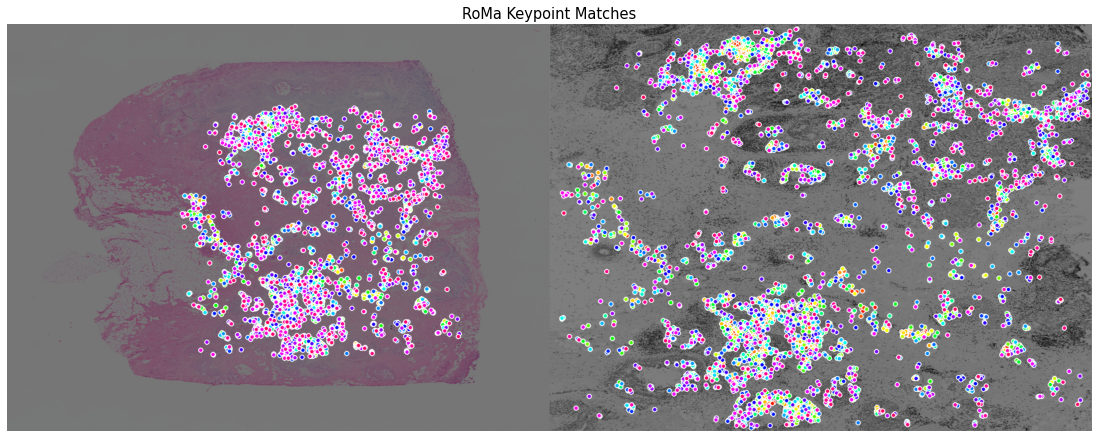

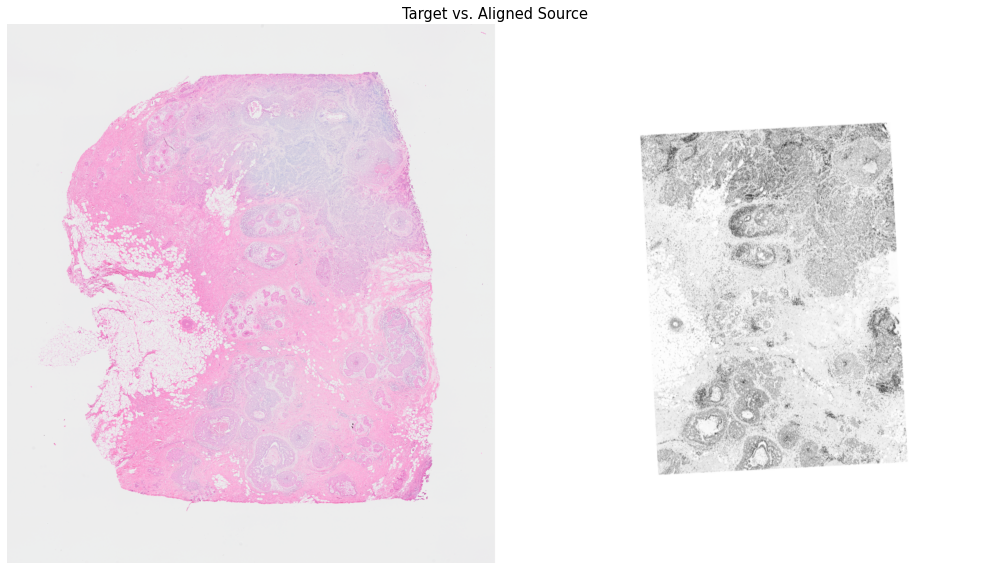

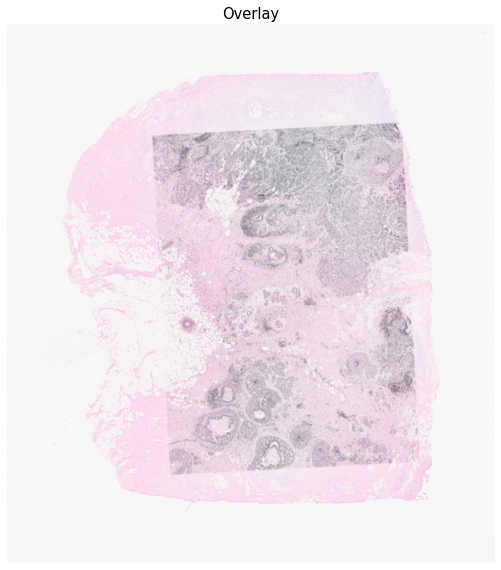

Alignment runtime: 61.3927 seconds
Done. Results saved to results/xenium_visium_breastcancer/img_2_img/XeniumtoHE/alignment
[OK] Scatter PNG saved: results/xenium_visium_breastcancer/img_2_img/XeniumtoHE/alignment/transformed_h5ad_scatter.png (1809x2000, background=black, shape=square, points=167780)


In [4]:
from PIL import ImageOps
from PIL import ImageEnhance
source_img = Image.open(source_image_path)
inverted_source_path = OUTPUT_ROOT / "source_image_inverted.tif"
inverted_img = ImageOps.invert(source_img)

# rotate source image to match the rotated landmark coordinates used earlier
rotated_source = rotate_image(inverted_img, 90)

# save the rotated/inverted source image
inverted_img = rotated_source
inverted_img.save(inverted_source_path, format="TIFF")
source_image_path = str(inverted_source_path)

PARAMS = {
    "sample_id": "XeniumtoHE",
    "target_image_path": target_image_path,
    "source_image_path": source_image_path,
    "source_h5ad_path": source_h5ad_path,
    "source_h5ad_spatial_key": "spatial",
    "Alignment_mode": "affine",
    "device": "cpu",
}
PARAMS

result = run_image_to_image_alignment(
    data_root=DATA_DIR,
    output_root=OUTPUT_ROOT,
    **PARAMS,
)

adata = anndata.read_h5ad(result["transformed_h5ad"])
transformed_coords = adata.obsm["spatial"]

In [7]:
transformed_coords

array([[1415.5261 ,  508.41788],
       [1415.0249 ,  504.93   ],
       [1414.6011 ,  508.7201 ],
       ...,
       [ 665.313  , 1660.88   ],
       [ 663.7619 , 1662.2354 ],
       [ 664.8001 , 1664.136  ]], shape=(167780, 2), dtype=float32)

(np.float64(-0.5), np.float64(1808.5), np.float64(1999.5), np.float64(-0.5))

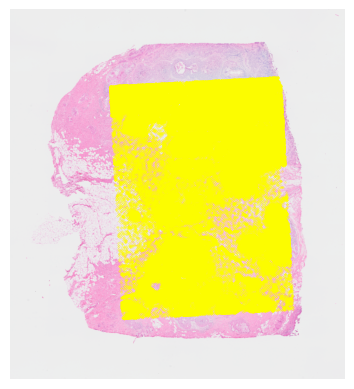

In [13]:
# save coordinates
transformed_coords = pd.DataFrame(transformed_coords, columns=["x", "y"])
transformed_coords.to_csv(str(OUTPUT_ROOT) + '/xenium_to_visium_affine_nl.csv.gz', compression='gzip', index=False)

# visualize landmarks
fig,ax = plt.subplots()
img = Image.open(result["target_section_visualization"])
ax.scatter(transformed_coords['x'], transformed_coords['y'], alpha=1, c="yellow", s=0.05)
ax.imshow(img)
ax.axis('off')

In [12]:
OUTPUT_ROOT

PosixPath('results/xenium_visium_breastcancer')

In [6]:
result["target_section_visualization"]

PosixPath('/Users/amanuky/Artur-man Dropbox/Artür Manukyan/Research/MDC/Projects/SpatialData/analysis/ImageAlignmentBenchmark/data/BreastCancer/Visium/tissue_hires_image_rotated.png')